Testing colour temperature throughout day

In [1]:
from utils.misc import (
    colourtemp_from_time, 
    lerp_color_temp,
    smoothstep_color_temp,
    legacy_get_colourtemp_for_time
)
from datetime import time
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Color Temperature, lerp')

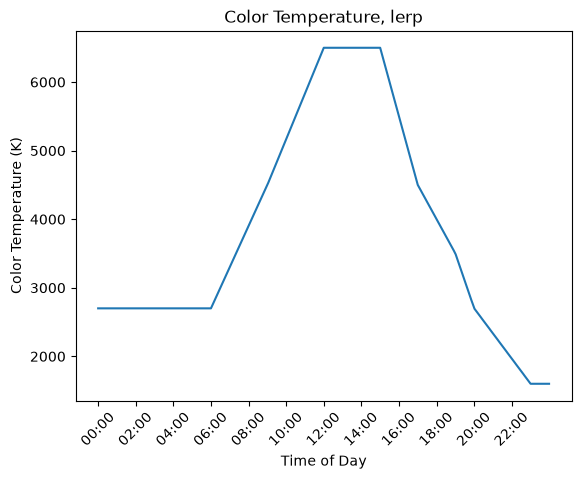

In [2]:
mapping: dict[str, int] = {}
col_temps: list[int] = []
times: list[str] = []

for i in range(24*60):
    hour, minute = divmod(i, 60)
    t = time(hour, minute)
    col_temps.append(colourtemp_from_time(t))
    times.append(f"{hour:02d}:{minute:02d}")

fig, ax = plt.subplots()
ax.plot(times, col_temps)

tick_indices = range(0, len(times), 120)
ax.set_xticks(tick_indices)
ax.set_xticklabels([times[i] for i in tick_indices])

for label in ax.get_xticklabels():
    label.set_rotation(45)

ax.set_xlabel('Time of Day')
ax.set_ylabel('Color Temperature (K)')
ax.set_title('Color Temperature, lerp')

Text(0.5, 1.0, 'Color Temperature, ease')

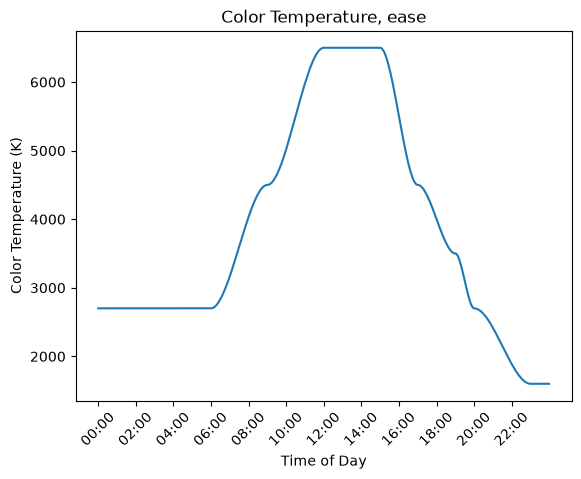

In [3]:
mapping: dict[str, int] = {}
col_temps: list[int] = []
times: list[str] = []

for i in range(24*60):
    hour, minute = divmod(i, 60)
    t = time(hour, minute)
    col_temps.append(colourtemp_from_time(t, func=smoothstep_color_temp))
    times.append(f"{hour:02d}:{minute:02d}")

fig, ax = plt.subplots()
ax.plot(times, col_temps)

tick_indices = range(0, len(times), 120)
ax.set_xticks(tick_indices)
ax.set_xticklabels([times[i] for i in tick_indices])

for label in ax.get_xticklabels():
    label.set_rotation(45)

ax.set_xlabel('Time of Day')
ax.set_ylabel('Color Temperature (K)')
ax.set_title('Color Temperature, ease')

C:\Users\gabeb\AppData\Local\Temp\ipykernel_87512\4264569234.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\gabeb\AppData\Local\Temp\ipykernel_87512\4264569234.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\gabeb\AppData\Local\Temp\ipykernel_87512\4264569234.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


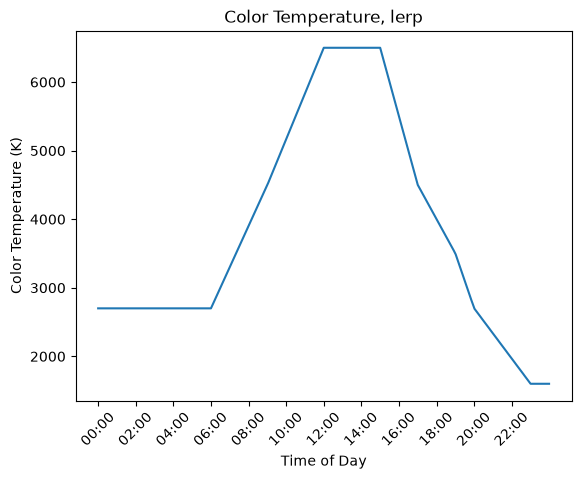

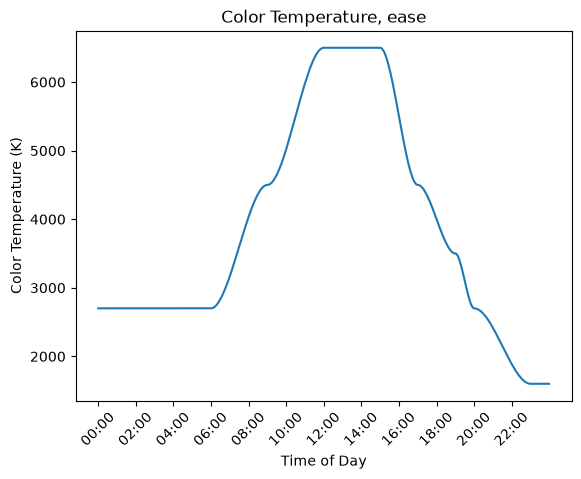

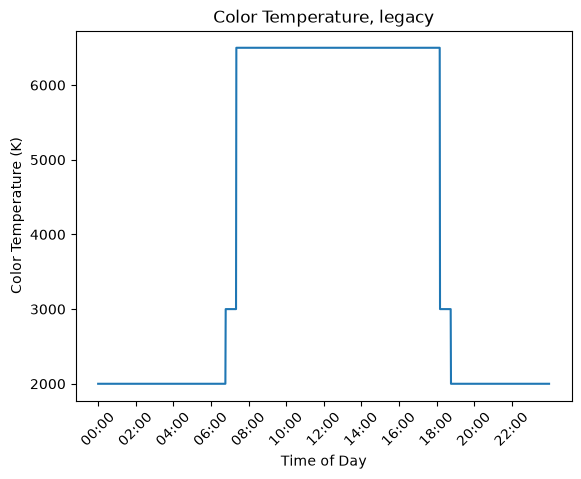

In [4]:
def plot_colourtemp(func, func_name:str):
    col_temps: list[int] = []
    times: list[str] = []

    for i in range(24*60):
        hour, minute = divmod(i, 60)
        t = time(hour, minute)
        col_temps.append(colourtemp_from_time(t, func))
        times.append(f"{hour:02d}:{minute:02d}")

    fig, ax = plt.subplots()
    ax.plot(times, col_temps)

    tick_indices = range(0, len(times), 120)
    ax.set_xticks(tick_indices)
    ax.set_xticklabels([times[i] for i in tick_indices])

    for label in ax.get_xticklabels():
        label.set_rotation(45)

    ax.set_xlabel('Time of Day')
    ax.set_ylabel('Color Temperature (K)')
    ax.set_title(f"Color Temperature, {func_name}")

    fig.show()

plot_colourtemp(lerp_color_temp, "lerp")
plot_colourtemp(smoothstep_color_temp, "ease")
plot_colourtemp(legacy_get_colourtemp_for_time, "legacy")